# Đánh giá dữ liệu


In [3]:
import pandas as pd
import numpy as np
from scipy.stats import skew
from scipy.stats import kurtosis
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
  

In [4]:
df=pd.read_csv("attritioon.csv")
df.head()


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,40,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,51,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,36,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,36,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,28,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [ ]:
# Kiem tra gia tri rong, trung lap
#print("giá trị trùng",df.duplicated().sum())
print(df.isnull().sum())

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

: 

In [6]:
# loai bo cot EmployeeCount, EmployeeNumber, Over18, StandardHours vi khong co y nghia trong viec du doan attrition
df.drop(['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'], axis=1, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EnvironmentSatisfaction   1470 non-null   int64 
 9   Gender                    1470 non-null   object
 10  HourlyRate                1470 non-null   int64 
 11  JobInvolvement            1470 non-null   int64 
 12  JobLevel                  1470 non-null   int64 
 13  JobRole                   1470 non-null   object
 14  JobSatisfaction         

In [7]:
# kiem tra kieu du lieu
cat_col = [col for col in df.columns if df[col].dtype == 'object']
num_col = [col for col in df.columns if df[col].dtype != 'object']
print('Categorical columns:', cat_col)
print('Numerical columns:', num_col)


Categorical columns: ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Numerical columns: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


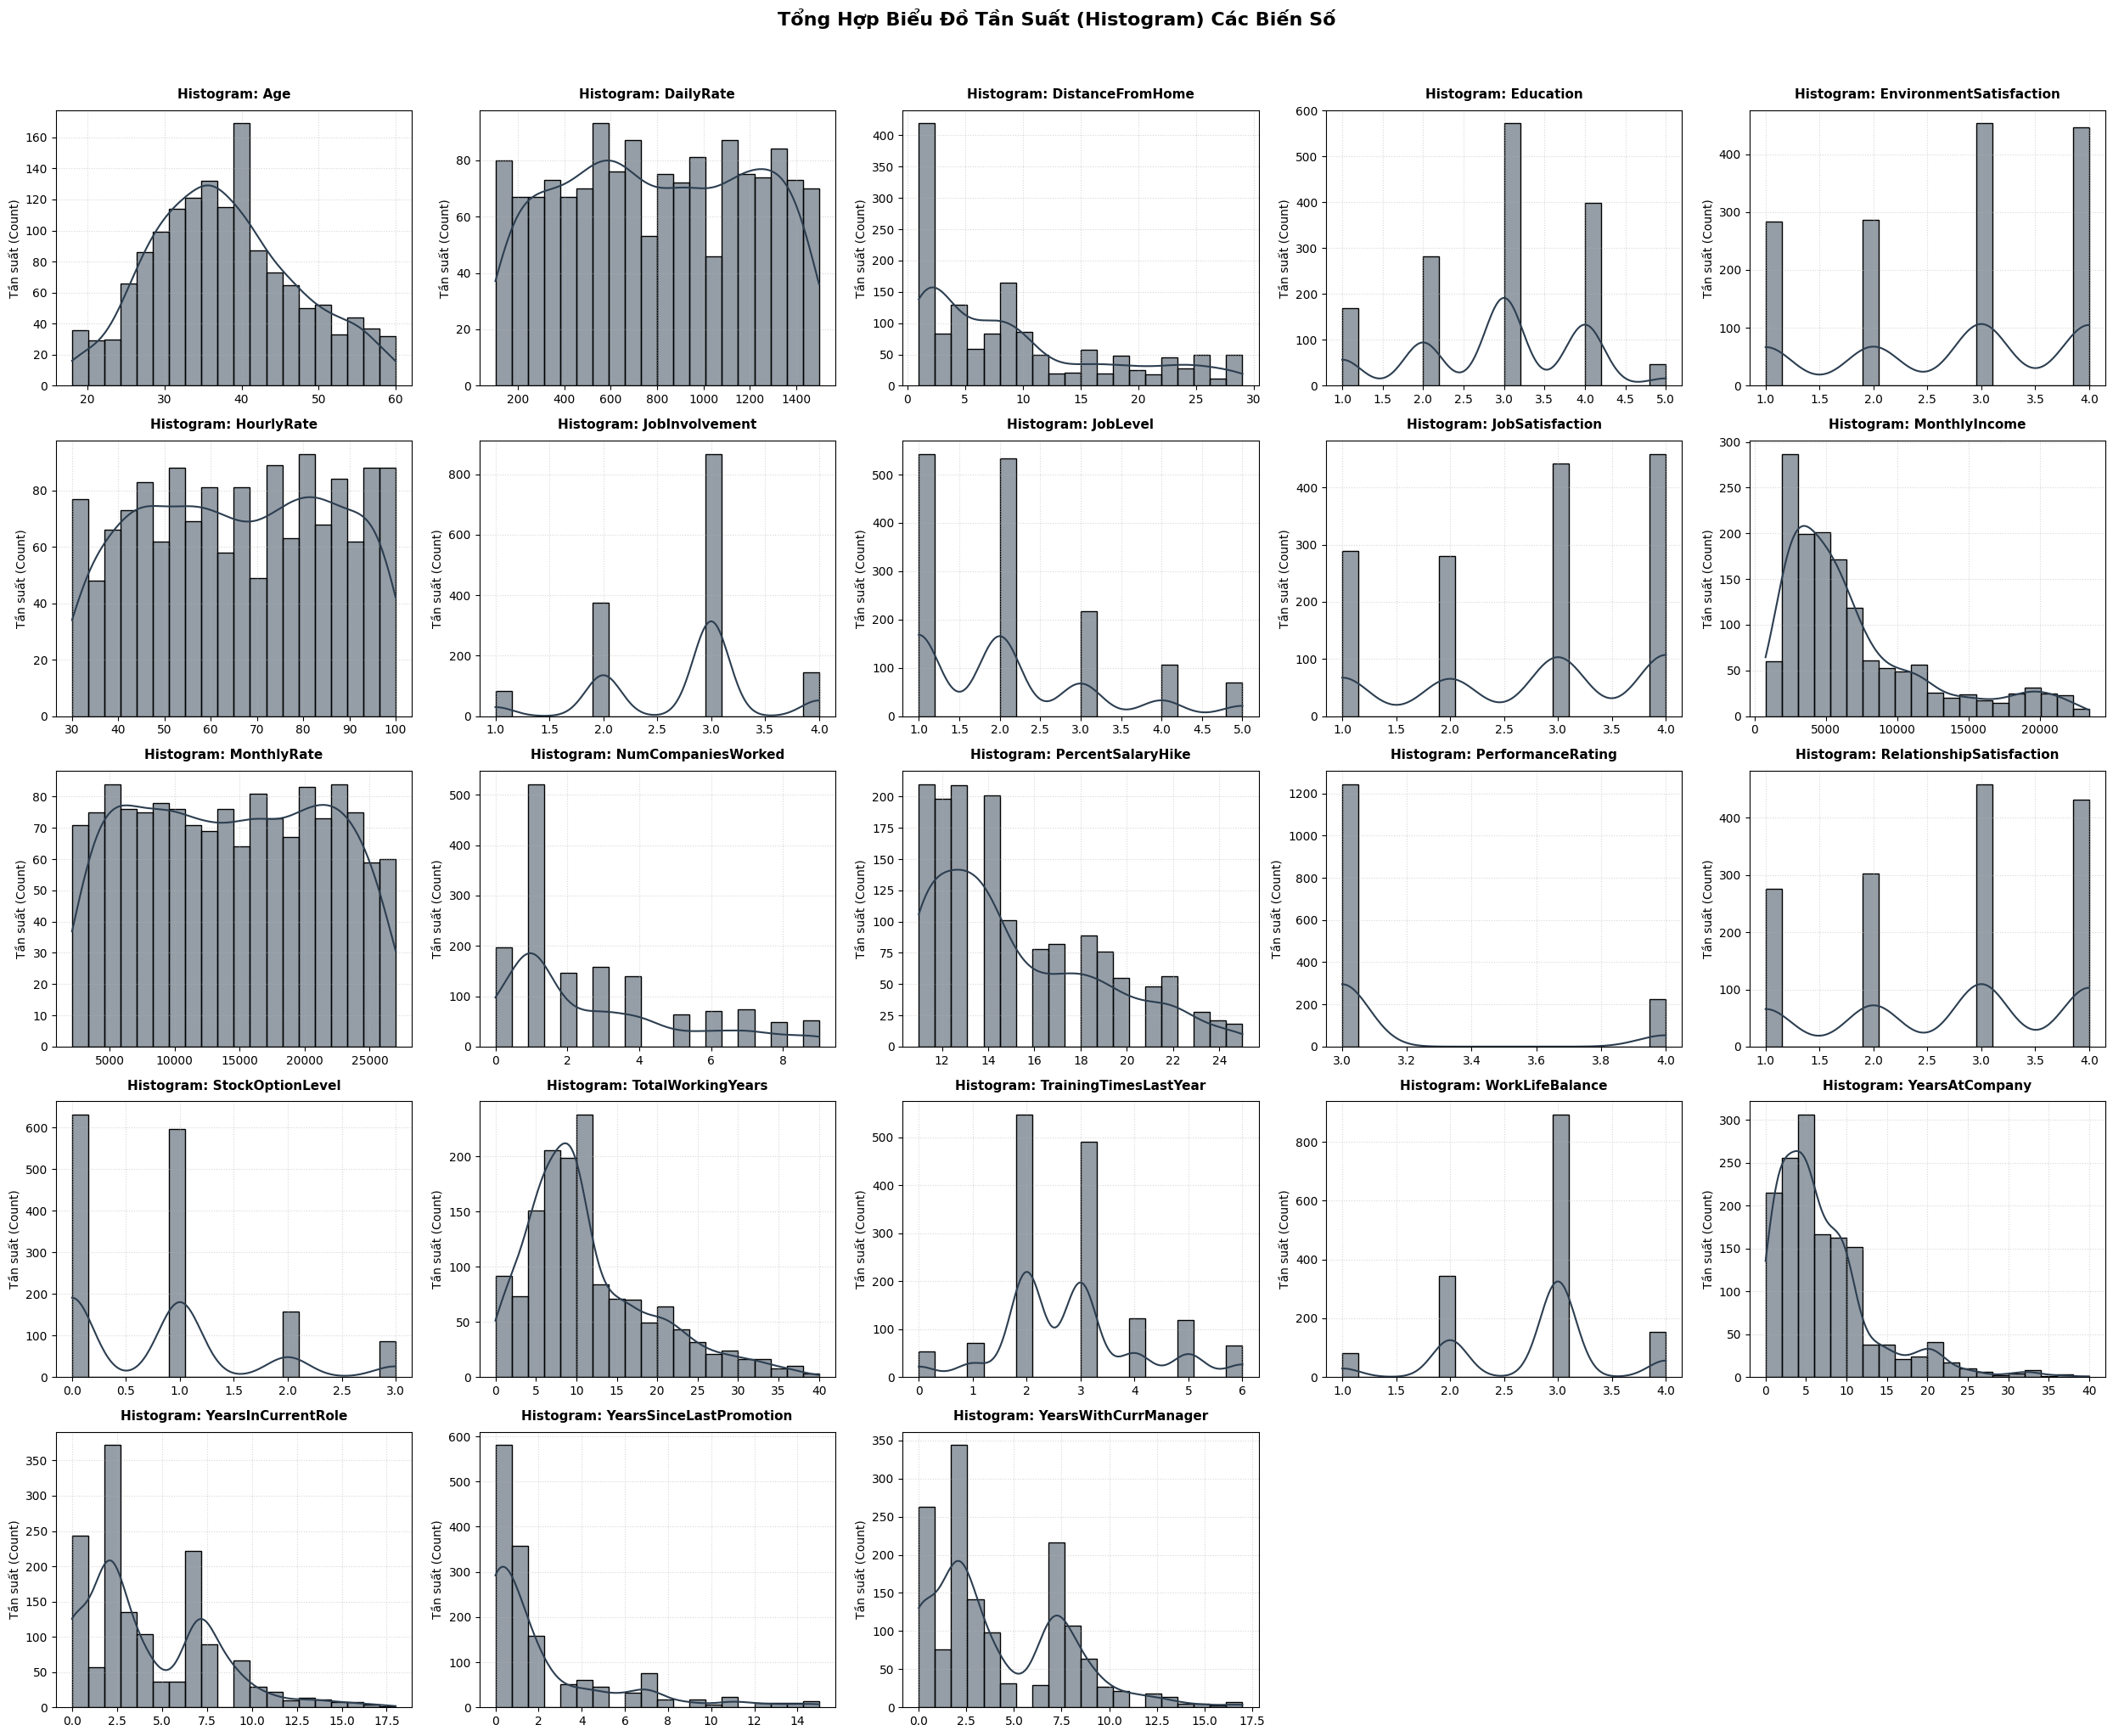

In [8]:
import math


# 1. Tự động cấu hình số lượng ô (Ví dụ: cố định mỗi hàng hiển thị tối đa 3 biểu đồ)
plots_per_row = 5
total_plots = len(num_col)
n_rows = math.ceil(total_plots / plots_per_row)

# 2. Tạo một khung hình (Figure) lớn chứa lưới các ô biểu đồ con (Subplots)
fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(5 * plots_per_row, 4 * n_rows))

# Làm phẳng mảng axes thành 1 chiều để lặp bằng index (i) một cách dễ dàng
axes = axes.flatten()

# 3. Vòng lặp vẽ Histogram cho từng cột số vào đúng ô của nó
for i, col in enumerate(num_col):
    # Dùng sns.histplot (hoặc đổi thành plt.hist(df[col]) nếu không muốn dùng seaborn)
    # kde=True sẽ vẽ thêm đường cong mật độ mịn đè lên cột histogram để dễ nhìn xu hướng
    sns.histplot(df[col], ax=axes[i], kde=True, color='#2c3e50', bins=20)
    
    # Định dạng tiêu đề và lưới cho từng ô nhỏ
    axes[i].set_title(f'Histogram: {col}', fontsize=11, fontweight='bold', pad=10)
    axes[i].set_xlabel('') # Ẩn nhãn trục X mặc định vì đã có tiêu đề
    axes[i].set_ylabel('Tần suất (Count)')
    axes[i].grid(True, linestyle=':', alpha=0.5)

# 4. BƯỚC QUAN TRỌNG: Ẩn các ô trống bị thừa 
# (Ví dụ bạn có 5 biến, lưới 2x3 = 6 ô, thì cần xóa ô thứ 6 đi)
for j in range(total_plots, len(axes)):
    fig.delaxes(axes[j])

# 5. Thiết lập tiêu đề chung cho cả bức tranh và tối ưu khoảng cách
plt.suptitle('Tổng Hợp Biểu Đồ Tần Suất (Histogram) Các Biến Số', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout() # Tự động căn chỉnh để tiêu đề và các trục không bị đè dính vào nhau

# 6. Hiển thị hình duy nhất chứa tất cả các đồ thị con
plt.show()


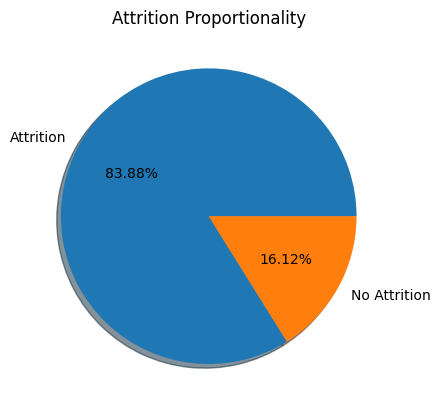

: 

In [ ]:
plt.pie(df['Attrition'].value_counts(),
        labels=['Attrition', 'No Attrition'],
        autopct='%.2f%%', shadow=True)
plt.title('Attrition Proportionality')       
plt.show()

In [9]:
df_log = df.copy()

for col in num_col:
    # Kiểm tra xem cột có bị lệch phải (skewness > 0.75) và không chứa số âm không
    if df_log[col].skew() > 0.75 and (df_log[col] >= 0).all():
        df_log[col] = np.log1p(df_log[col])  # Sửa từ num_col thành col



<Axes: xlabel='MonthlyIncome', ylabel='Density'>

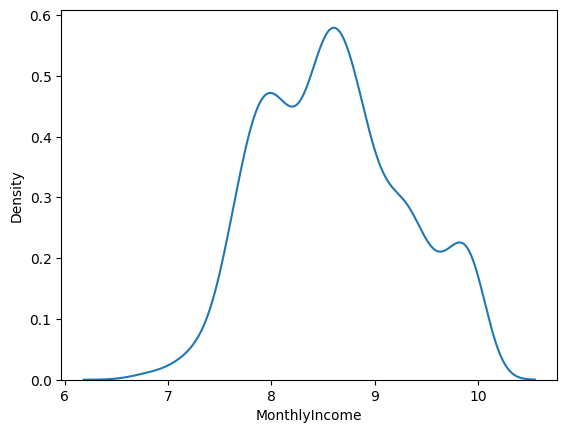

In [10]:
sns.kdeplot(df_log['MonthlyIncome'])

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder

# Khai báo danh sách các cột theo nhóm
ordinal_features = ["BusinessTravel","MaritalStatus","OverTime"]
ordinal_categories = [["Non-Travel", "Travel_Rarely", "Travel_Frequently"],["Single", "Married", "Divorced"],["No", "Yes"]]

nominal_features = ["Department", "EducationField", "JobRole"]
binary_features = ["Gender"]

# Tạo tiền xử lý
preprocessor = ColumnTransformer(
    transformers=[
        (
            "ordinal",
            OrdinalEncoder(categories=ordinal_categories),
            ordinal_features,
        ),
        ("binary", OrdinalEncoder(), binary_features),
        ("nominal", OneHotEncoder(drop="first", sparse_output=False), nominal_features),
    ],
    remainder="passthrough",  # Giữ lại các cột số nguyên bản
)
from sklearn.model_selection import train_test_split

X = df_log.drop('Attrition', axis=1)
y = df['Attrition'].map({"No": 0, "Yes": 1})  # Chuyển đổi nhãn thành số

Xtrain, Xtest, ytrain, ytest = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_encoded = preprocessor.fit_transform(Xtrain)

# Chỉ TRANSFORM trên tập Test (tuyệt đối không dùng fit lại)
X_test_encoded = preprocessor.transform(Xtest)
feature_names = preprocessor.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_encoded, columns=feature_names, index=Xtrain.index)
X_test_df = pd.DataFrame(X_test_encoded, columns=feature_names, index=Xtest.index)

In [16]:
X_train_df

,ordinal__BusinessTravel,ordinal__MaritalStatus,ordinal__OverTime,binary__Gender,nominal__Department_Research & Development,nominal__Department_Sales,nominal__EducationField_Life Sciences,nominal__EducationField_Marketing,nominal__EducationField_Medical,nominal__EducationField_Other,...,remainder__PerformanceRating,remainder__RelationshipSatisfaction,remainder__StockOptionLevel,remainder__TotalWorkingYears,remainder__TrainingTimesLastYear,remainder__WorkLifeBalance,remainder__YearsAtCompany,remainder__YearsInCurrentRole,remainder__YearsSinceLastPromotion,remainder__YearsWithCurrManager
1194,1.0,2.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,1.386294,3.0,1.386294,3.401197,2.0,3.0,1.386294,1.098612,0.693147,1.098612
128,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.386294,3.0,0.693147,1.386294,2.0,3.0,1.098612,0.693147,1.098612,0.693147
810,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,1.386294,4.0,0.693147,3.178054,3.0,3.0,2.564949,2.302585,1.609438,2.302585
478,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,1.386294,3.0,0.000000,2.079442,1.0,3.0,2.079442,1.609438,0.000000,1.945910
491,2.0,2.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,1.386294,2.0,0.693147,2.397895,3.0,3.0,2.197225,2.079442,1.609438,2.079442
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1213,1.0,2.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,...,1.609438,2.0,0.693147,1.386294,2.0,3.0,1.386294,1.098612,0.000000,1.098612
963,1.0,2.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,1.386294,4.0,0.693147,2.484907,3.0,3.0,2.079442,2.079442,0.693147,2.079442
734,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,...,1.386294,1.0,0.693147,1.609438,3.0,2.0,1.609438,1.386294,0.693147,0.693147
1315,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.609438,4.0,0.693147,2.772589,2.0,3.0,0.693147,0.000000,0.000000,0.000000


In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train_df)
X_train_= pd.DataFrame(X_train,columns=feature_names, index=Xtrain.index)
X_test=scaler.transform(X_test_df)

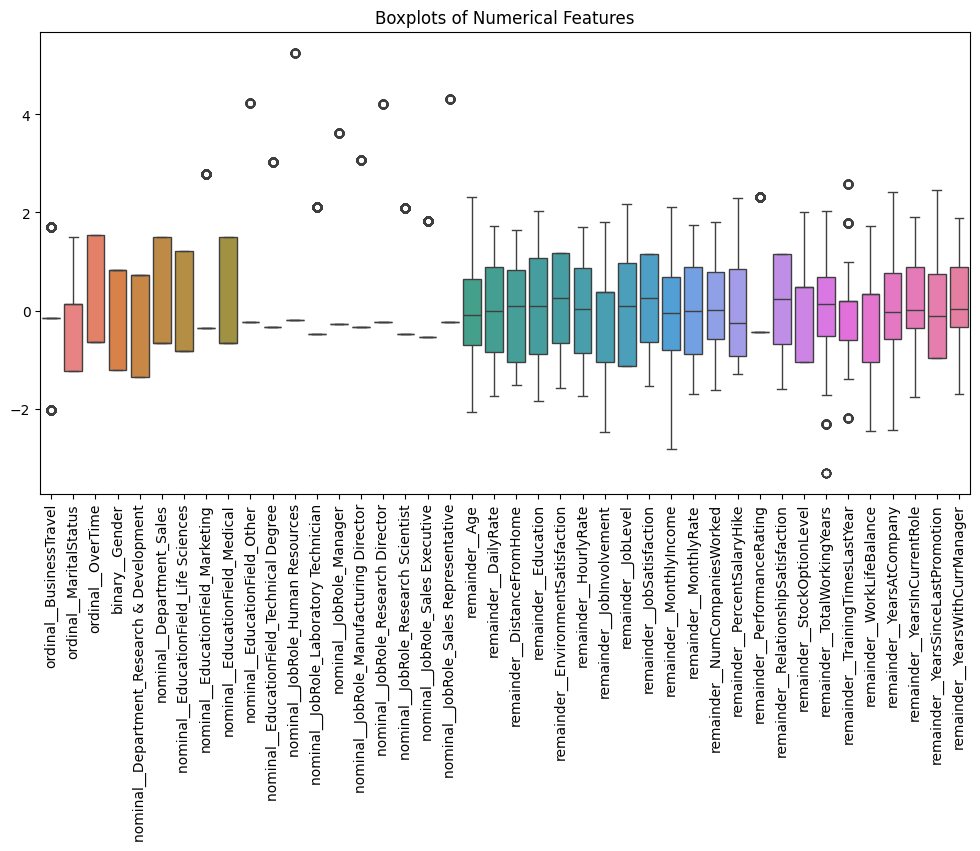

In [13]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train_)
plt.xticks(rotation=90)
plt.title("Boxplots of Numerical Features")
plt.show()

In [ ]:
'''from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train, ytrain = smote.fit_resample(X_train, ytrain)'''

'from imblearn.over_sampling import SMOTE\nsmote = SMOTE(random_state=42)\nX_train, ytrain = smote.fit_resample(X_train, ytrain)'

: 

# Sử dụng phương pháp lọc để chọn đặc trưng với mutual_info_classif

In [14]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif, chi2

# 1. Khởi tạo bộ lọc, chọn ra 10 đặc trưng tốt nhất dựa trên điểm số F-value
selector = SelectKBest(
    score_func=lambda X, y: mutual_info_classif(X, y, random_state=42),
    k=15
)

# 2. Áp dụng vào dữ liệu
X_filter = selector.fit_transform(X_train, ytrain)


# 3. Xem các đặc trưng được giữ lại
selected_features = X_train_df.columns[selector.get_support()]
print("Các đặc trưng được chọn (Filter):", list(selected_features))


Các đặc trưng được chọn (Filter): ['ordinal__BusinessTravel', 'ordinal__OverTime', 'nominal__Department_Sales', 'nominal__EducationField_Other', 'nominal__JobRole_Laboratory Technician', 'nominal__JobRole_Research Director', 'remainder__Age', 'remainder__JobInvolvement', 'remainder__JobLevel', 'remainder__MonthlyIncome', 'remainder__TotalWorkingYears', 'remainder__WorkLifeBalance', 'remainder__YearsAtCompany', 'remainder__YearsInCurrentRole', 'remainder__YearsWithCurrManager']


In [20]:
X_train

array([[-0.16150971,  1.49916852, -0.64565275, ..., -0.36381238,
        -0.11481268, -0.33632307],
       [-0.16150971,  0.1282337 ,  1.54882017, ..., -0.8791286 ,
         0.38565587, -0.84151709],
       [-0.16150971,  0.1282337 , -0.64565275, ...,  1.16634817,
         1.01617166,  1.16378103],
       ...,
       [-0.16150971,  0.1282337 , -0.64565275, ...,  0.00181029,
        -0.11481268, -0.84151709],
       [-0.16150971,  0.1282337 , -0.64565275, ..., -1.7600675 ,
        -0.9703693 , -1.70515198],
       [ 1.70060225,  1.49916852, -0.64565275, ..., -0.8791286 ,
         0.38565587, -0.33632307]], shape=(1176, 42))

In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score , f1_score, precision_score, recall_score


model_lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model_lr.fit(X_filter, ytrain)

# Đánh giá trên tập huấn luyện
y_pred_train = model_lr.predict(X_filter)
y_pred_test = model_lr.predict(selector.transform(X_test))

print("Classification Report trên tập Test:")
print(classification_report(ytest, y_pred_test))
print("Classification Report trên tập Train: ")
print(classification_report(ytrain,y_pred_train))
model_lr.fit(X_train,ytrain)
y_pred_lr=model_lr.predict(X_test)
print("Classification toan dac trung:")
print(classification_report(ytest,y_pred_lr))

Classification Report trên tập Test:
              precision    recall  f1-score   support

           0       0.94      0.85      0.89       247
           1       0.48      0.72      0.58        47

    accuracy                           0.83       294
   macro avg       0.71      0.79      0.73       294
weighted avg       0.87      0.83      0.84       294

Classification Report trên tập Train: 
              precision    recall  f1-score   support

           0       0.97      0.86      0.91       986
           1       0.53      0.85      0.66       190

    accuracy                           0.86      1176
   macro avg       0.75      0.85      0.78      1176
weighted avg       0.90      0.86      0.87      1176

Classification toan dac trung:
              precision    recall  f1-score   support

           0       0.93      0.87      0.90       247
           1       0.50      0.66      0.57        47

    accuracy                           0.84       294
   macro avg       0.

: 

In [ ]:
# Ramdom Forest với đặc trưng chọn bằng phương pháp lọc
from sklearn.ensemble import RandomForestClassifier
model_rf = RandomForestClassifier(n_estimators=100, max_depth=6, min_samples_leaf=6,  random_state=42, class_weight='balanced')
model_rf.fit(X_filter, ytrain)
y_pred_rf_test = model_rf.predict(selector.transform(X_test))
print("Classification Report trên tập Test:")
print(classification_report(ytest, y_pred_rf_test))
print("Classification Report trên tập Train:")
print(classification_report(ytrain,model_rf.predict(X_filter)))



Classification Report trên tập Test:
              precision    recall  f1-score   support

           0       0.95      0.86      0.90       247
           1       0.51      0.77      0.62        47

    accuracy                           0.85       294
   macro avg       0.73      0.81      0.76       294
weighted avg       0.88      0.85      0.86       294

Classification Report trên tập Train:
              precision    recall  f1-score   support

           0       0.98      0.89      0.93       986
           1       0.62      0.88      0.73       190

    accuracy                           0.89      1176
   macro avg       0.80      0.89      0.83      1176
weighted avg       0.92      0.89      0.90      1176



: 

In [ ]:
# Su dung toan bo dac trung (khong thong qua matual_info_classif)
model_rf.fit(X_train_encoded,ytrain)
y_pred_rf_ecode=model_rf.predict(X_test_encoded)
print(classification_report(ytest,y_pred_rf_ecode))
print(classification_report(ytrain,model_rf.predict(X_train_encoded)))

              precision    recall  f1-score   support

           0       0.95      0.91      0.93       247
           1       0.61      0.74      0.67        47

    accuracy                           0.88       294
   macro avg       0.78      0.83      0.80       294
weighted avg       0.90      0.88      0.89       294

              precision    recall  f1-score   support

           0       0.98      0.92      0.95       986
           1       0.70      0.89      0.78       190

    accuracy                           0.92      1176
   macro avg       0.84      0.91      0.87      1176
weighted avg       0.93      0.92      0.92      1176



: 

In [ ]:
# XGBoost
import xgboost as xgb
from sklearn.metrics import classification_report, accuracy_score , f1_score, precision_score, recall_score,roc_auc_score

model_boost = xgb.XGBClassifier(
    n_estimators=300,      # Number of trees to build
    learning_rate=0.05,     # Step size shrinkage (eta)
    max_depth=2,
    min_child_weight=1,    
    random_state=42,
    subsample=0.8,
    colsample_bytree=0.7

  
)
model_boost.fit(X_filter, ytrain)
y_pred_boost_test = model_boost.predict(selector.transform(X_test))
print("Classification Report trên tập Test:")
print(classification_report(ytest, y_pred_boost_test))
print("ROC-AUC Score:", roc_auc_score(ytest, y_pred_boost_test))
print("Classification Report trên tập Train:")
print(classification_report(ytrain, model_boost.predict(X_filter)))

Classification Report trên tập Test:
              precision    recall  f1-score   support

           0       0.92      0.96      0.94       247
           1       0.74      0.55      0.63        47

    accuracy                           0.90       294
   macro avg       0.83      0.76      0.79       294
weighted avg       0.89      0.90      0.89       294

ROC-AUC Score: 0.7583771211990697
Classification Report trên tập Train:
              precision    recall  f1-score   support

           0       0.94      0.99      0.96       986
           1       0.93      0.66      0.77       190

    accuracy                           0.94      1176
   macro avg       0.93      0.82      0.87      1176
weighted avg       0.94      0.94      0.93      1176



: 

In [ ]:
model_xgb = xgb.XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8,
                          scale_pos_weight=5.189473684210526, eval_metric='logloss', random_state=42)
model_xgb.fit(X_train, ytrain)

# đánh giá với ngưỡng mặc định 0.5
y_pred_xgb = model_xgb.predict(X_test)

print("Accuracy trên tập Test:", accuracy_score(ytest, y_pred_xgb))
print("F1 Score trên tập Test:", f1_score(ytest, y_pred_xgb))
print("Precision Score trên tập Test:", precision_score(ytest, y_pred_xgb))
print("Recall Score trên tập Test:", recall_score(ytest, y_pred_xgb))
print("Classification Report trên tập Test:")
print(classification_report(ytest, y_pred_xgb))

Accuracy trên tập Test: 0.9115646258503401
F1 Score trên tập Test: 0.717391304347826
Precision Score trên tập Test: 0.7333333333333333
Recall Score trên tập Test: 0.7021276595744681
Classification Report trên tập Test:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95       247
           1       0.73      0.70      0.72        47

    accuracy                           0.91       294
   macro avg       0.84      0.83      0.83       294
weighted avg       0.91      0.91      0.91       294



: 

In [ ]:
# Su dung toan bo dac trung (khong thong qua matual_info_classif)
model_xgb.fit(X_train_encoded,ytrain)
y_pred_xb_ecode=model_xgb.predict(X_test_encoded)
print(classification_report(ytest,y_pred_xb_ecode))
print(classification_report(ytrain,model_xgb.predict(X_train_encoded)))

              precision    recall  f1-score   support

           0       0.94      0.95      0.95       247
           1       0.73      0.70      0.72        47

    accuracy                           0.91       294
   macro avg       0.84      0.83      0.83       294
weighted avg       0.91      0.91      0.91       294

              precision    recall  f1-score   support

           0       1.00      0.97      0.98       986
           1       0.85      0.98      0.91       190

    accuracy                           0.97      1176
   macro avg       0.93      0.98      0.95      1176
weighted avg       0.97      0.97      0.97      1176



: 

# lựa chọn đặc trưng bằng phương pháp wrapper

In [ ]:
from sklearn.feature_selection import RFE

# 1. Khởi tạo bộ chọn đặc trưng RFE, chọn ra 10 đặc trưng tốt nhất
selector_rfe = RFE(estimator=model_rf, n_features_to_select=15)

# 2. Áp dụng vào dữ liệu
X_rf_rfe = selector_rfe.fit_transform(X_train, ytrain)

# 3. Xem các đặc trưng được giữ lại
selected_features_rfe = X_train_df.columns[selector_rfe.get_support()]
print("Các đặc trưng được chọn (RFE):", list(selected_features_rfe))

Các đặc trưng được chọn (RFE): ['ordinal__OverTime', 'nominal__JobRole_Sales Executive', 'remainder__Age', 'remainder__DailyRate', 'remainder__DistanceFromHome', 'remainder__EnvironmentSatisfaction', 'remainder__HourlyRate', 'remainder__JobLevel', 'remainder__MonthlyIncome', 'remainder__MonthlyRate', 'remainder__NumCompaniesWorked', 'remainder__StockOptionLevel', 'remainder__TotalWorkingYears', 'remainder__YearsAtCompany', 'remainder__YearsWithCurrManager']


: 

In [ ]:
test=selector_rfe.transform(X_test)
model_rf.fit(X_rf_rfe, ytrain)
y_pred_rf_test_rfe = model_rf.predict(test)
print("Classification Report trên tập Test:")
print(classification_report(ytest, y_pred_rf_test_rfe))
print("Classification Report trên tập Train:")
print(classification_report(ytrain,model_rf.predict(X_rf_rfe)))


Classification Report trên tập Test:
              precision    recall  f1-score   support

           0       0.95      0.90      0.93       247
           1       0.59      0.77      0.67        47

    accuracy                           0.88       294
   macro avg       0.77      0.83      0.80       294
weighted avg       0.89      0.88      0.88       294

Classification Report trên tập Train:
              precision    recall  f1-score   support

           0       0.98      0.92      0.95       986
           1       0.68      0.91      0.78       190

    accuracy                           0.92      1176
   macro avg       0.83      0.91      0.86      1176
weighted avg       0.93      0.92      0.92      1176



: 

In [ ]:
# logistic regression
selector_lr_rfe= RFE(estimator=model_lr,n_features_to_select=15)
X_lr_rfe = selector_lr_rfe.fit_transform(X_train, ytrain)
X_lr_rfe_test = selector_lr_rfe.transform(X_test)
model_lr.fit(X_lr_rfe,ytrain)
y_pred_lr_rfe = model_lr.predict(X_lr_rfe_test)
print("Classification Report trên tập Test:")
print(classification_report(ytest,y_pred_lr_rfe))

Classification Report trên tập Test:
              precision    recall  f1-score   support

           0       0.93      0.88      0.91       247
           1       0.52      0.66      0.58        47

    accuracy                           0.85       294
   macro avg       0.72      0.77      0.74       294
weighted avg       0.87      0.85      0.85       294



: 

In [ ]:
#xgb
selector_xgb_rfe= RFE(estimator=model_xgb)
X_xgb_rfe=selector_xgb_rfe.fit_transform(X_train,ytrain)
X_xgb_rfe_test = selector_xgb_rfe.transform(X_test)
model_xgb.fit(X_xgb_rfe,ytrain)
y_pred_xgb_rfe = model_xgb.predict(X_xgb_rfe_test)
print("Classification Report trên tập Test:")
print(classification_report(ytest,y_pred_xgb_rfe))

Classification Report trên tập Test:
              precision    recall  f1-score   support

           0       0.95      0.92      0.93       247
           1       0.64      0.72      0.68        47

    accuracy                           0.89       294
   macro avg       0.79      0.82      0.81       294
weighted avg       0.90      0.89      0.89       294



: 

# Phương pháp embedded

In [ ]:

from sklearn.feature_selection import SelectFromModel

# 1. Khởi tạo mô hình có hình phạt L1 (C càng nhỏ, phạt càng nặng -> càng ít biến được giữ lại)
embedded_model = model_xgb

# 2. Sử dụng SelectFromModel để tự động nhặt các đặc trưng có hệ số khác 0
selector_eb = SelectFromModel(embedded_model,random_state=42)
X_embedded = selector_eb.fit_transform(X_train, ytrain)
X_test_ebedded=selector_eb.transform(X_test)
# 3. Xem các đặc trưng được giữ lại
selected_eb_features = X_train_df.columns[selector.get_support()]
print("Các đặc trưng được chọn (Embedded):", list(selected_eb_features))


Các đặc trưng được chọn (Embedded): ['ordinal__MaritalStatus', 'ordinal__OverTime', 'nominal__JobRole_Human Resources', 'nominal__JobRole_Laboratory Technician', 'nominal__JobRole_Manager', 'nominal__JobRole_Manufacturing Director', 'remainder__Age', 'remainder__HourlyRate', 'remainder__JobLevel', 'remainder__MonthlyIncome', 'remainder__NumCompaniesWorked', 'remainder__TotalWorkingYears', 'remainder__YearsAtCompany', 'remainder__YearsInCurrentRole', 'remainder__YearsWithCurrManager']


: 

In [ ]:
embedded_model.fit(X_embedded,ytrain)
y_pred_eb = embedded_model.predict(X_test_ebedded)
print("Classification Report trên tập Test:")
print(classification_report(ytest,y_pred_eb))


Classification Report trên tập Test:
              precision    recall  f1-score   support

           0       0.95      0.90      0.92       247
           1       0.58      0.74      0.65        47

    accuracy                           0.87       294
   macro avg       0.77      0.82      0.79       294
weighted avg       0.89      0.87      0.88       294



: 